In [4]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [5]:
from pathlib import Path

# Kaggle dataset (already extracted, read-only)
DATA_DIR = Path("/kaggle/input/datasets/vallabhgopu/abnormal-behavior-detection-v1i-yolov8")

for split in ["train", "valid", "test"]:
    folder = DATA_DIR / split / "images"
    count = len(list(folder.glob("*.jpg")))
    print(f"{split}: {count} images")

print("\nDataset configuration:")
print((DATA_DIR / "data.yaml").read_text())

train: 1862 images
valid: 1847 images
test: 0 images

Dataset configuration:
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 6
names: ['0', '1', '2', 'fall', 'fight', 'normal']

roboflow:
  workspace: abnormal-behavior-detection
  project: abnormal-behavior-detection-5geje
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/abnormal-behavior-detection/abnormal-behavior-detection-5geje/dataset/1


In [6]:
import hashlib
import re
import yaml
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Reproduce the exact train/val/test split of the 2D CNN and ViT notebooks
# (same cleaning, same video groups, same seed), so every model is tested on the same videos.
CHUNK = 100
SPLIT_SEED = 42
names = yaml.safe_load((DATA_DIR / "data.yaml").read_text())["names"]
MERGE = {"0": "normal", "1": "fall", "2": "fight", "normal": "normal", "fall": "fall", "fight": "fight"}

def group_of(fname):
    """Source-video id, as in the 2D notebooks (long numbered sequences -> blocks of CHUNK frames)."""
    stem = re.sub(r"_(png|jpg|jpeg)$", "", fname.split(".rf.")[0])
    prefix, num = re.match(r"^(.*?)(\d+)$", stem).groups()
    if prefix in ("", "p"):
        return f"{prefix or 'num'}_{int(num) // CHUNK}"
    return prefix

rows, md5_seen = [], set()
for split in ("train", "valid", "test"):
    for img in sorted((DATA_DIR / split / "images").glob("*")):
        md5 = hashlib.md5(img.read_bytes()).hexdigest()
        if md5 in md5_seen:  # exact duplicate export -> keep the first copy
            continue
        md5_seen.add(md5)
        lbl = DATA_DIR / split / "labels" / f"{img.stem}.txt"
        classes = {MERGE[names[int(l.split()[0])]] for l in lbl.read_text().splitlines() if l.strip()} if lbl.exists() else set()
        if classes:
            label = "fight" if "fight" in classes else "fall" if "fall" in classes else "normal"
            rows.append({"group": group_of(img.name), "label": label})

df2d = pd.DataFrame(rows)
trval_idx, _ = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
                    .split(df2d, df2d.label, df2d.group))
trval = df2d.iloc[trval_idx]
tr_i, va_i = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SPLIT_SEED)
                  .split(trval, trval.label, trval.group))
df2d["split"] = "test"
df2d.loc[trval.index[tr_i], "split"] = "train"
df2d.loc[trval.index[va_i], "split"] = "val"

sizes = df2d.split.value_counts().to_dict()
assert sizes == {"train": 2074, "val": 741, "test": 784}, f"Split differs from the 2D notebooks: {sizes}. scikit-learn 1.8 changed StratifiedGroupKFold shuffling; run `pip install scikit-learn==1.7.2` and restart."
GROUP_SPLIT = df2d.groupby("group").split.first().to_dict()
print("2D split reproduced:", sizes)


2D split reproduced: {'train': 2074, 'test': 784, 'val': 741}


In [7]:
import re
from pathlib import Path
from collections import defaultdict, Counter

CLASS_NAMES = ["normal", "fall", "fight"]
# Raw ids 0/1/2 are a second naming of normal/fall/fight (checked visually), so merge them.
LABEL_MAP = {5: 0, 3: 1, 4: 2, 0: 0, 1: 1, 2: 2}

CLIP_LEN = 4
MAX_FRAME_GAP = 20

# Combine the original folders, then split by source video later.
# Keep each source/frame combination together.
frame_records = defaultdict(list)

for split in ["train", "valid"]:
    for image_path in sorted((DATA_DIR / split / "images").glob("*.jpg")):
        original_name = image_path.name.split(".rf.")[0]

        match = re.fullmatch(
            r"(.+?)(?:-frame_|-rgb-)(\d+)_png",
            original_name
        )
        if not match:
            continue

        source, frame_number = match.groups()
        label_path = (
            DATA_DIR / split / "labels" / f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            continue

        ids = {
            int(line.split()[0])
            for line in label_path.read_text().splitlines()
            if line.strip()
        }

        # Exclude empty labels and frames containing both fall and fight.
        classes = {LABEL_MAP[i] for i in ids}
        target = None
        if classes and not {1, 2}.issubset(classes):
            # A frame with abnormal and normal people is abnormal.
            target = 2 if 2 in classes else 1 if 1 in classes else 0

        frame_records[(source, int(frame_number))].append(
            (str(image_path), target)
        )

sequences = defaultdict(list)

for (source, frame_number), records in sorted(frame_records.items()):
    targets = {target for _, target in records}

    # Reject conflicting or ambiguous versions of a frame.
    if len(targets) != 1 or None in targets:
        continue

    path, target = records[0]
    sequences[source].append((frame_number, path, target))

clips = []

for source, frames in sorted(sequences.items()):
    frames.sort()

    # Training clips overlap (stride 1) to get more training data; overlap inside the
    # training set cannot leak into evaluation. Validation/test clips do not overlap
    # (stride CLIP_LEN), so every evaluation frame is counted once, as in the 2D models.
    start = 0
    while start + CLIP_LEN <= len(frames):
        window = frames[start:start + CLIP_LEN]
        frame_numbers = [item[0] for item in window]
        targets = {item[2] for item in window}

        gaps = [
            b - a for a, b in zip(frame_numbers, frame_numbers[1:])
        ]

        if len(targets) != 1 or max(gaps) > MAX_FRAME_GAP:
            start += 1
            continue

        group = group_of(Path(window[0][1]).name)

        clips.append({
            "paths": [item[1] for item in window],
            "label": window[0][2],
            "source": source,
            "group": group,
            "split": GROUP_SPLIT[group],
            "frame_numbers": frame_numbers,
        })
        start += 1 if GROUP_SPLIT[group] == "train" else CLIP_LEN

print("Total candidate clips:", len(clips))
print("Source groups:", len({clip["group"] for clip in clips}))

counts = Counter(clip["label"] for clip in clips)
for index, name in enumerate(CLASS_NAMES):
    print(f"{name}: {counts[index]} clips")

assert clips, "No usable clips found."
assert all(counts[i] > 0 for i in range(3)), "A class has no clips."

Total candidate clips: 1081
Source groups: 80
normal: 167 clips
fall: 253 clips
fight: 661 clips


In [8]:
from collections import Counter

# Each clip inherits the 2D split of its source video.
train_clips = [c for c in clips if c["split"] == "train"]
val_clips = [c for c in clips if c["split"] == "val"]
test_clips = [c for c in clips if c["split"] == "test"]

# Confirm that source groups do not overlap.
train_groups = {c["group"] for c in train_clips}
val_groups = {c["group"] for c in val_clips}
test_groups = {c["group"] for c in test_clips}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

for name, subset in [
    ("Training", train_clips),
    ("Validation", val_clips),
    ("Testing", test_clips)
]:
    counts = Counter(c["label"] for c in subset)
    print(f"\n{name}: {len(subset)} clips")
    for i, class_name in enumerate(CLASS_NAMES):
        print(f"  {class_name}: {counts[i]}")

    assert all(counts[i] > 0 for i in range(3)), (
        f"{name} is missing a class. Share this output before continuing."
    )

print("\nSource-group overlap check passed.")


Training: 884 clips
  normal: 134
  fall: 193
  fight: 557

Validation: 113 clips
  normal: 5
  fall: 34
  fight: 74

Testing: 84 clips
  normal: 28
  fall: 26
  fight: 30

Source-group overlap check passed.


In [9]:
import random
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 112
BATCH_SIZE = 16

class CrowdClipDataset(Dataset):
    def __init__(self, clips, augment=False):
        self.clips = clips
        self.augment = augment

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, index):
        clip = self.clips[index]

        # Apply the same augmentation to every frame in a clip.
        flip = self.augment and random.random() < 0.5
        frames = []

        for path in clip["paths"]:
            with Image.open(path) as image:
                image = image.convert("RGB").resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    Image.Resampling.BILINEAR
                )

                if flip:
                    image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

                array = np.asarray(image, dtype=np.float32) / 255.0
                frames.append(torch.from_numpy(array).permute(2, 0, 1))

        # Shape: channels × frames × height × width
        video = torch.stack(frames, dim=1)
        return video, torch.tensor(clip["label"], dtype=torch.long)


train_loader = DataLoader(
    CrowdClipDataset(train_clips, augment=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    CrowdClipDataset(val_clips),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    CrowdClipDataset(test_clips),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


class Crowd3DCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16),
            nn.ReLU(),
            nn.MaxPool3d((1, 2, 2)),

            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d((2, 2, 2)),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = Crowd3DCNN().to(device)

# Calculate class weights from TRAINING data only.
class_counts = np.bincount(
    [clip["label"] for clip in train_clips],
    minlength=len(CLASS_NAMES)
)

class_weights = len(train_clips) / (
    len(CLASS_NAMES) * class_counts
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights, dtype=torch.float32, device=device
    )
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Check one batch without updating batch-normalization statistics.
videos, targets = next(iter(train_loader))
model.eval()
with torch.no_grad():
    outputs = model(videos.to(device))

print("Device:", device)
print("Input shape:", tuple(videos.shape))
print("Output shape:", tuple(outputs.shape))
print("Class order:", CLASS_NAMES)
print("Class weights:", class_weights.round(3))
print("Model ready!")

Device: cuda
Input shape: (16, 3, 4, 112, 112)
Output shape: (16, 3)
Class order: ['normal', 'fall', 'fight']
Class weights: [2.199 1.527 0.529]
Model ready!


In [10]:
import copy
import json
import time
from pathlib import Path

import pandas as pd
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

OUTPUT_DIR = Path("/kaggle/working/anika_3dcnn_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 25
history = []
best_val_f1 = -1.0
best_epoch = 0

# Save the exact split for reproducibility.
with open(OUTPUT_DIR / "data_splits.json", "w") as file:
    json.dump({
        "class_names": CLASS_NAMES,
        "train": train_clips,
        "validation": val_clips,
        "test": test_clips
    }, file, indent=2)


def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_weight = 0.0
    true_labels = []
    predicted_labels = []

    with torch.set_grad_enabled(training):
        for videos, targets in loader:
            videos = videos.to(device)
            targets = targets.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(videos)

            # Sum weighted losses and normalize by sample weights.
            # This also gives a consistent epoch-level loss.
            loss_sum = F.cross_entropy(
                logits,
                targets,
                weight=criterion.weight,
                reduction="sum"
            )
            weight_sum = criterion.weight[targets].sum()
            loss = loss_sum / weight_sum

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss_sum.item()
            total_weight += weight_sum.item()

            true_labels.extend(targets.cpu().tolist())
            predicted_labels.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

    return {
        "loss": total_loss / total_weight,
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )
    }


start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_macro_f1": val_metrics["macro_f1"]
    })

    # Save graph data after every epoch.
    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / "training_history.csv", index=False
    )

    improved = val_metrics["macro_f1"] > best_val_f1

    if improved:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_macro_f1": best_val_f1,
            "class_names": CLASS_NAMES,
            "image_size": IMAGE_SIZE,
            "clip_length": CLIP_LEN
        }, OUTPUT_DIR / "best_model.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Train acc: {train_metrics['accuracy']:.3f} | "
        f"Val acc: {val_metrics['accuracy']:.3f} | "
        f"Val F1: {val_metrics['macro_f1']:.3f}"
        + ("  ← best saved" if improved else ""),
        flush=True
    )

print(f"\nTraining finished in {(time.time() - start_time) / 60:.1f} minutes")
print(f"Best epoch: {best_epoch}")
print(f"Best validation macro F1: {best_val_f1:.4f}")

Epoch 01/25 | Train loss: 0.5595 | Val loss: 0.4388 | Train acc: 0.842 | Val acc: 0.788 | Val F1: 0.715  ← best saved
Epoch 02/25 | Train loss: 0.4417 | Val loss: 0.4936 | Train acc: 0.902 | Val acc: 0.779 | Val F1: 0.743  ← best saved
Epoch 03/25 | Train loss: 0.3732 | Val loss: 1.3024 | Train acc: 0.925 | Val acc: 0.593 | Val F1: 0.363
Epoch 04/25 | Train loss: 0.3470 | Val loss: 0.3577 | Train acc: 0.923 | Val acc: 0.885 | Val F1: 0.880  ← best saved
Epoch 05/25 | Train loss: 0.3475 | Val loss: 0.3630 | Train acc: 0.913 | Val acc: 0.805 | Val F1: 0.761
Epoch 06/25 | Train loss: 0.3608 | Val loss: 0.4331 | Train acc: 0.917 | Val acc: 0.805 | Val F1: 0.826
Epoch 07/25 | Train loss: 0.3406 | Val loss: 0.2956 | Train acc: 0.925 | Val acc: 0.858 | Val F1: 0.742
Epoch 08/25 | Train loss: 0.3200 | Val loss: 0.5453 | Train acc: 0.931 | Val acc: 0.805 | Val F1: 0.696
Epoch 09/25 | Train loss: 0.3073 | Val loss: 0.7334 | Train acc: 0.925 | Val acc: 0.743 | Val F1: 0.554
Epoch 10/25 | Train lo

Evaluated checkpoint: epoch 13

TEST RESULTS
              precision    recall  f1-score   support

      normal     1.0000    0.6429    0.7826        28
        fall     0.7429    1.0000    0.8525        26
       fight     0.9677    1.0000    0.9836        30

    accuracy                         0.8810        84
   macro avg     0.9035    0.8810    0.8729        84
weighted avg     0.9089    0.8810    0.8760        84



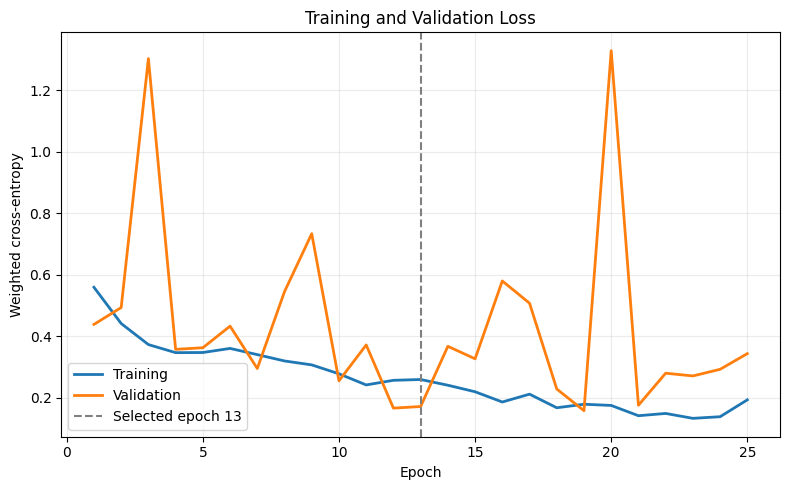

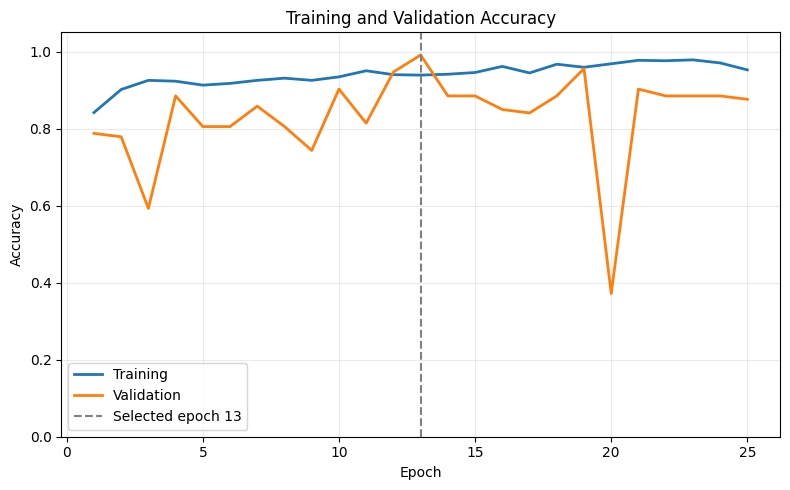

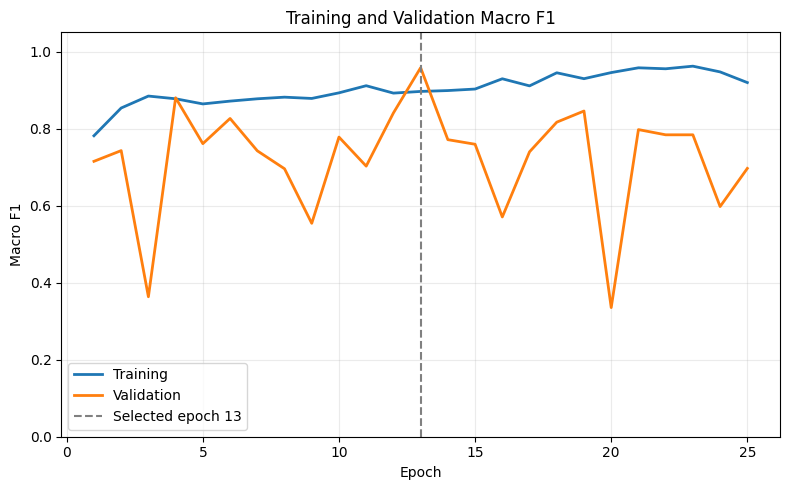

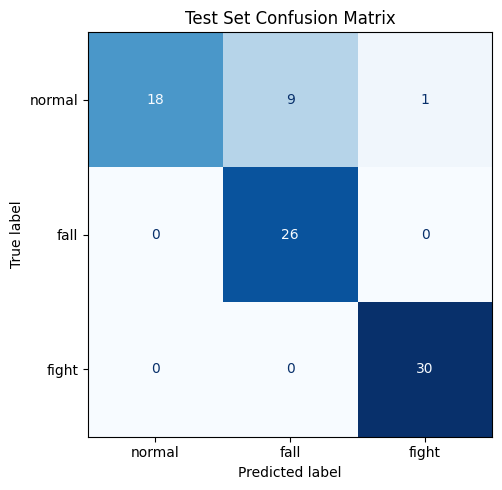

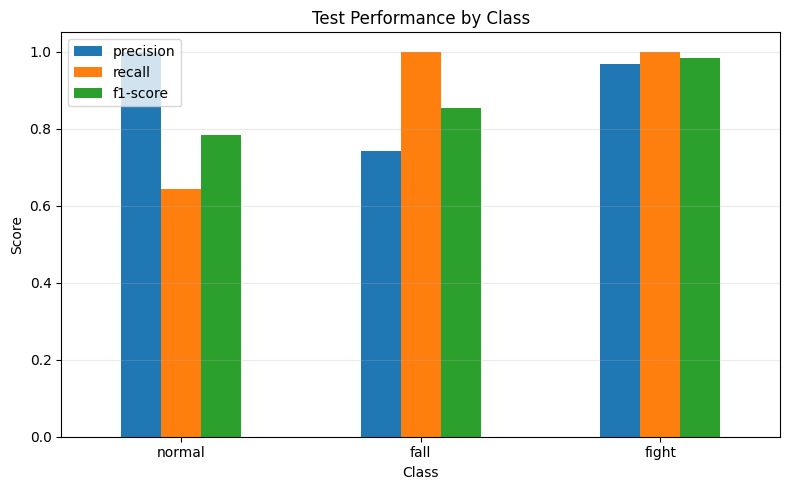


Results and graphs saved to /kaggle/working/Anika_3D_CNN_Final_Results.zip


In [11]:
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the model selected using validation data.
checkpoint = torch.load(
    OUTPUT_DIR / "best_model.pt",
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Evaluate the held-out test set.
y_true, y_pred, probabilities = [], [], []

with torch.no_grad():
    for videos, targets in test_loader:
        logits = model(videos.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()

        probabilities.extend(probs.tolist())
        y_true.extend(targets.tolist())
        y_pred.extend(probs.argmax(axis=1).tolist())

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print(f"Evaluated checkpoint: epoch {checkpoint['epoch']}")
print("\nTEST RESULTS")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "test_classification_report.csv"
)

with open(OUTPUT_DIR / "test_metrics.json", "w") as file:
    json.dump(report, file, indent=2)

# Save each test prediction with its source information.
prediction_rows = []
for clip, actual, predicted, probs in zip(
    test_clips, y_true, y_pred, probabilities
):
    row = {
        "source": clip["source"],
        "group": clip["group"],
        "frame_numbers": json.dumps(clip["frame_numbers"]),
        "true_class": CLASS_NAMES[actual],
        "predicted_class": CLASS_NAMES[predicted],
    }
    row.update({
        f"probability_{name}": probs[i]
        for i, name in enumerate(CLASS_NAMES)
    })
    prediction_rows.append(row)

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / "test_predictions.csv", index=False
)

# Training and validation curves.
history_df = pd.read_csv(OUTPUT_DIR / "training_history.csv")

for metric, title, ylabel in [
    ("loss", "Training and Validation Loss", "Weighted cross-entropy"),
    ("accuracy", "Training and Validation Accuracy", "Accuracy"),
    ("macro_f1", "Training and Validation Macro F1", "Macro F1")
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        history_df["epoch"], history_df[f"train_{metric}"],
        label="Training", linewidth=2
    )
    ax.plot(
        history_df["epoch"], history_df[f"val_{metric}"],
        label="Validation", linewidth=2
    )
    ax.axvline(
        checkpoint["epoch"], color="gray", linestyle="--",
        label=f"Selected epoch {checkpoint['epoch']}"
    )

    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    if metric != "loss":
        ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{metric}_curve.png", dpi=300)
    plt.show()
    plt.close(fig)

# Test confusion matrix: rows are actual, columns are predicted.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

pd.DataFrame(
    cm,
    index=[f"actual_{name}" for name in CLASS_NAMES],
    columns=[f"predicted_{name}" for name in CLASS_NAMES]
).to_csv(OUTPUT_DIR / "test_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Test Set Confusion Matrix")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=300)
plt.show()
plt.close(fig)

# Per-class test precision, recall and F1.
class_metrics = pd.DataFrame({
    name: {
        metric: report[name][metric]
        for metric in ["precision", "recall", "f1-score"]
    }
    for name in CLASS_NAMES
}).T

ax = class_metrics.plot.bar(figsize=(8, 5), rot=0)
ax.set(
    title="Test Performance by Class",
    xlabel="Class",
    ylabel="Score",
    ylim=(0, 1.05)
)
ax.grid(axis="y", alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_class_metrics.png", dpi=300)
plt.show()
plt.close(fig)

# Zip everything, including the saved model; download it from the Kaggle Output panel.
archive_path = shutil.make_archive(
    "/kaggle/working/Anika_3D_CNN_Final_Results",
    "zip",
    OUTPUT_DIR
)
print(f"\nResults and graphs saved to {archive_path}")